# District context and bounded parallel runs

Run a small district using existing APIs and inspect its conservative neighbour representation.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

`DistrictPlan(buildings=...)` groups explicit target buildings in one metric coordinate frame. `resolved_buildings()` returns each target with the others represented as shading context. `run(..., workers=2)` executes their independent simulations with a bounded number of workers.

The context gallery shows the distinction between a target and its neighbours. District context is not a coupled urban thermal model: neighbours have shading geometry, not exchanged indoor heat or shared HVAC. The helper considers every other target, making it appropriate for a small district demonstration rather than a national all-to-all neighbourhood search.

Reference: [An explicitly supplied shading neighbour](../../docs/figures/viewer-custom.png). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


### Independent buildings share shading context

Other buildings become shading geometry for each target, not jointly solved thermal zones or a district heating network. Coincident peaks require aligned intervals. National-scale execution additionally needs spatial partitioning, restartable dispatch and explicit input/acceptance tracking; workers only bound this local batch.

The following original diagram is conceptual API guidance; the later charts and tables report the computed example values.

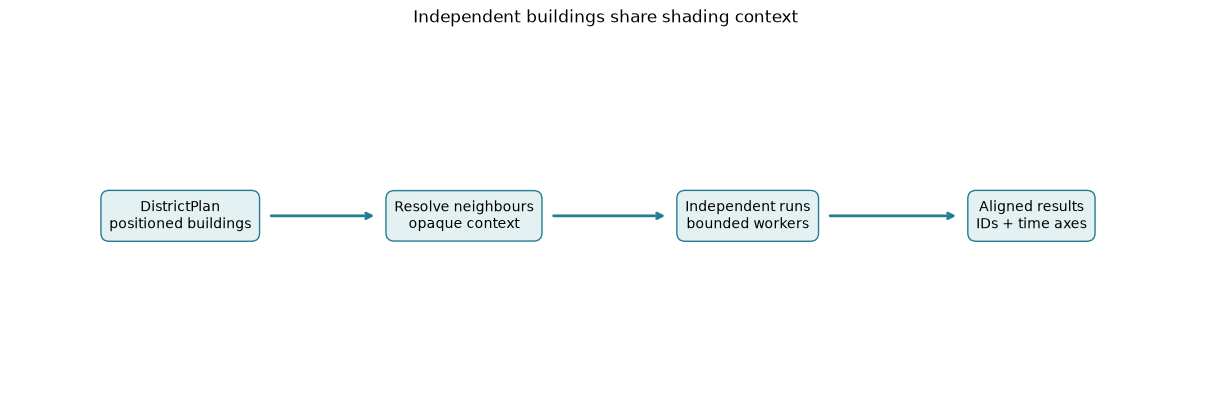

In [2]:
from demo.support.common import flow
flow(['DistrictPlan\npositioned buildings', 'Resolve neighbours\nopaque context', 'Independent runs\nbounded workers', 'Aligned results\nIDs + time axes'], 'Independent buildings share shading context', figsize=(12, 4))

## Place buildings in one metric frame

District targets must share a coordinate system, have unique identifiers and use zero scene orientation. Other targets become shading extrusions; there is no inter-building thermal coupling.

### Read the code and output

Identifiers must be unique and orientation must already be resolved in the common coordinate frame. The example positions footprints with a 50 m spacing and changes storey count explicitly. Inspect the neighbour count before running to confirm that each target receives the intended context.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

,target,neighbours,floor_area_m2
0,target-0,2,300.0
1,target-1,2,600.0
2,target-2,2,900.0


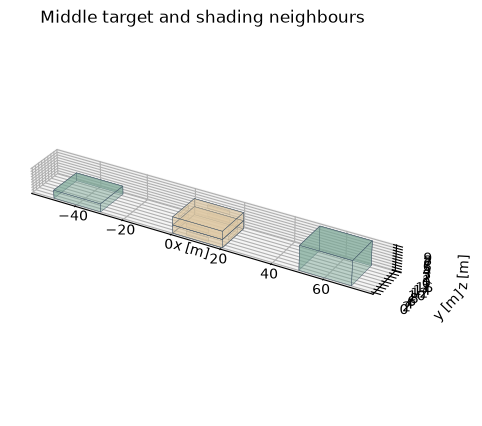

In [3]:
from shapely.geometry import box
base=building()
targets=[]
for i in range(3):
    fp=Footprint(exterior=tuple(box(i*50,0,i*50+20,15).exterior.coords))
    targets.append(base.updated(identifier=f"target-{i}",geometry=geometry(fp,storeys=i+1,source_crs="local_metres")))
plan=DistrictPlan(buildings=tuple(targets))
resolved=tuple(plan.resolved_buildings())
assert all(len(b.context.buildings)==2 for b in resolved)
table([{ "target":b.identifier,"neighbours":len(b.context.buildings),"floor_area_m2":b.geometry.conditioned_floor_area_m2} for b in resolved])
preview(resolved[1],"Middle target and shading neighbours")

## Run with two workers

The district helper uses bounded threads around independent engine processes. A failed worker propagates its exception; completed artifacts remain on disk.

### Read the code and output

Two workers limit simultaneous tasks rather than changing the simulated physics. A worker failure propagates while completed artifacts remain available. Runtime and failure handling become important as detail grows; scaling this example should not begin by loading an entire national stock as one district.

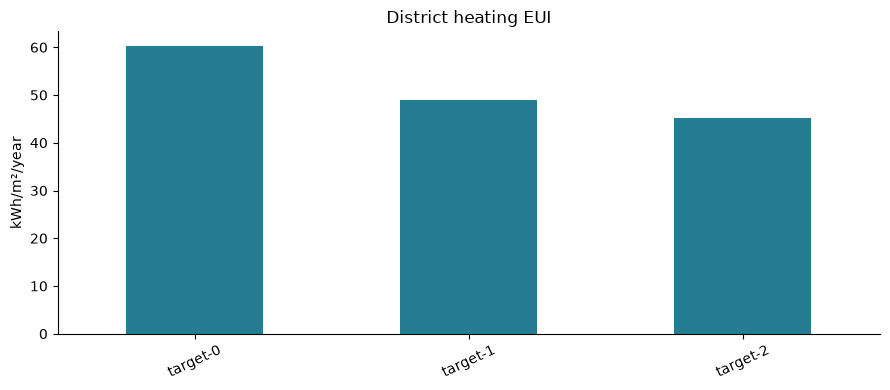

In [4]:
results=plan.run(OUT/"district",energyplus=engine(),workers=2)
assert set(results)=={b.identifier for b in targets}
bars({name:r.scalars["space_heating_demand_eui_kwh_m2"] for name,r in results.items()},"kWh/m²/year","District heating EUI")

## Aggregate aligned hourly demands

The peak of a sum is not generally the sum of each building peak. Align the validated time axes before aggregation.

### Read the code and output

Coincident aggregation requires matching calendars and intervals. The peak of the summed profile is less than or equal to the sum of individual peaks; equality occurs only when their maxima coincide. The result is hourly-average power, not a subhourly design load for a real district network.

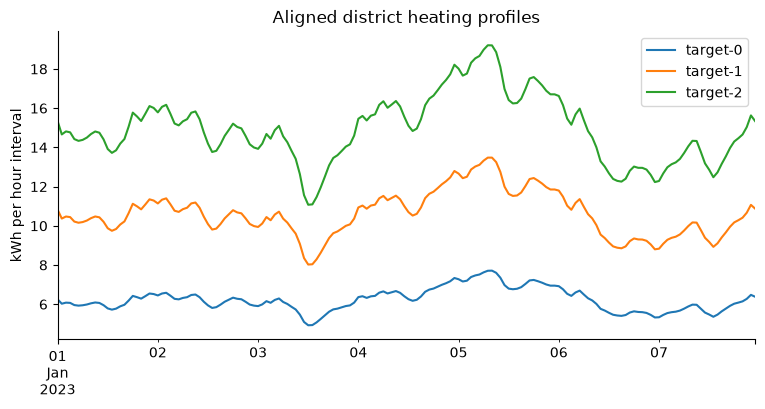

,field,value
0,coincident_hourly_average_peak_kW,40.39362885000903
1,sum_of_individual_hourly_peaks_kW,40.39935843830443


,field,value
0,coincident_hourly_average_peak_kW,40.39362885000903
1,sum_of_individual_hourly_peaks_kW,40.39935843830443


In [5]:
profiles=pd.DataFrame({name:result_frame(r).space_heating_demand_kwh for name,r in results.items()})
assert not profiles.isna().any().any()
fig, ax = plt.subplots(figsize=(9, 4))
profiles.iloc[:168].plot(ax=ax, ylabel="kWh per hour interval",title="Aligned district heating profiles"); plt.show(); plt.close(fig)
table({"coincident_hourly_average_peak_kW":profiles.sum(axis=1).max(),"sum_of_individual_hourly_peaks_kW":profiles.max().sum()})

## Interpretation and next experiment

DistrictPlan includes every other target as context, so it is a small-district helper. National spatial partitioning and neighbour selection belong upstream.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.